<a href="https://colab.research.google.com/github/dusandraq/Machine-Learning-Homework/blob/main/MLhw7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)

(60000, 28, 28, 1)

(10000, 28, 28, 1)

(60000, 10)

(10000, 10)



/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 447s 528ms/step - accuracy: 0.8411 - loss: 0.4353 - val_accuracy: 0.8825 - val_loss: 0.3176
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 456s 540ms/step - accuracy: 0.8929 - loss: 0.2921 - val_accuracy: 0.8893 - val_loss: 0.2908
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 447s 530ms/step - accuracy: 0.9053 - loss: 0.2537 - val_accuracy: 0.8992 - val_loss: 0.2775
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 530s 563ms/step - accuracy: 0.9144 - loss: 0.2285 - val_accuracy: 0.8970 - val_loss: 0.2910
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 486s 575ms/step - accuracy: 0.9212 - loss: 0.2082 - val_accuracy: 0.9023 - val_loss: 0.2804
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 53ms/step - accuracy: 0.8973 - loss: 0.2958
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 51ms/step
0: 0.0000007000%
1: 0.0000000057%
2: 0.0000000025%
3: 0.0000000592%
4: 0.0000000232%
5: 0.0009024609%
6: 0.0000004461%
7: 0.0513055362%
8: 0.0000006830%
9: 99.9477803707%
0: 0.0000000020%
1: 0.0000000000%
2: 0.0000000000%
3: 

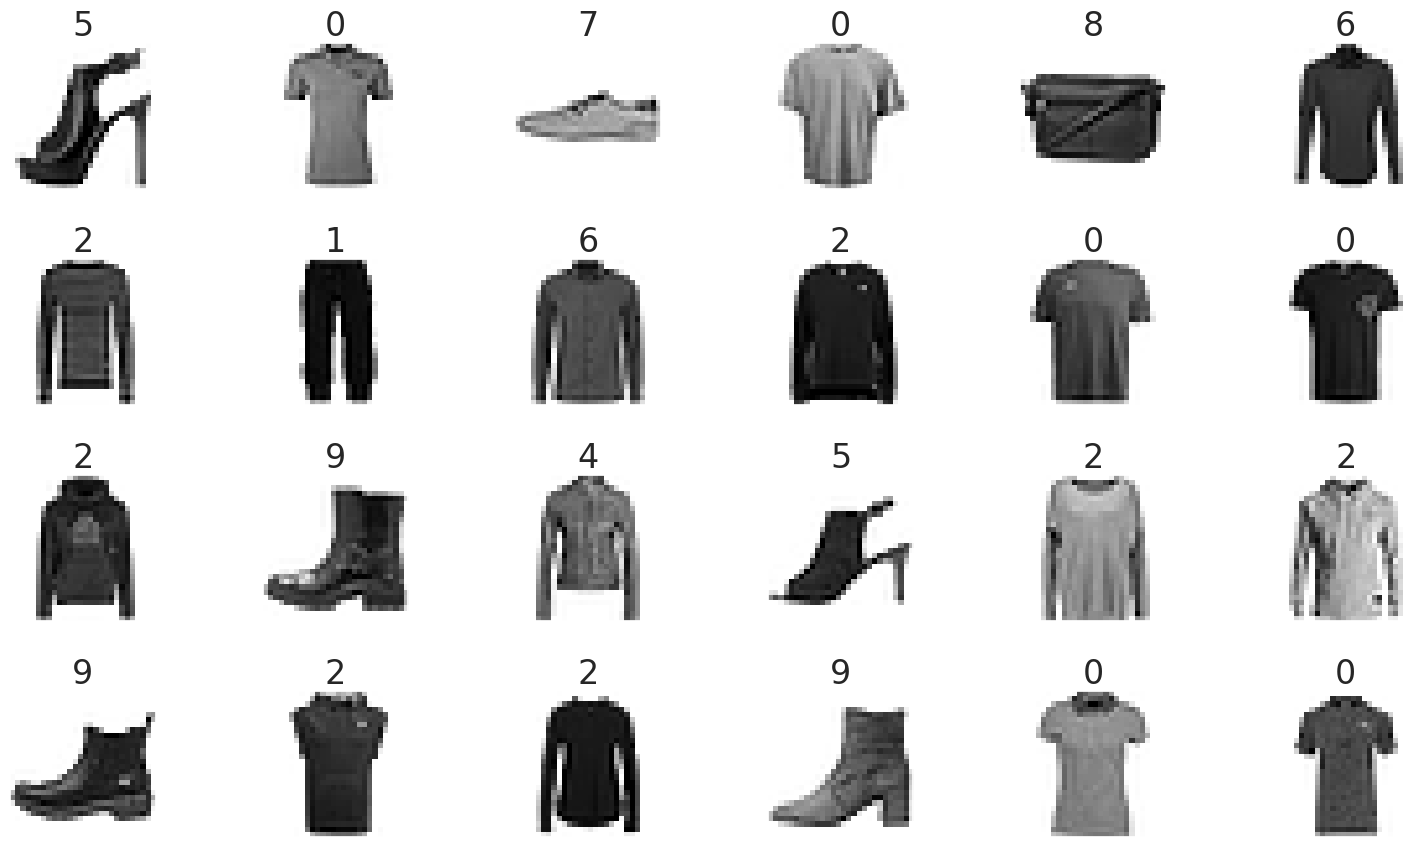

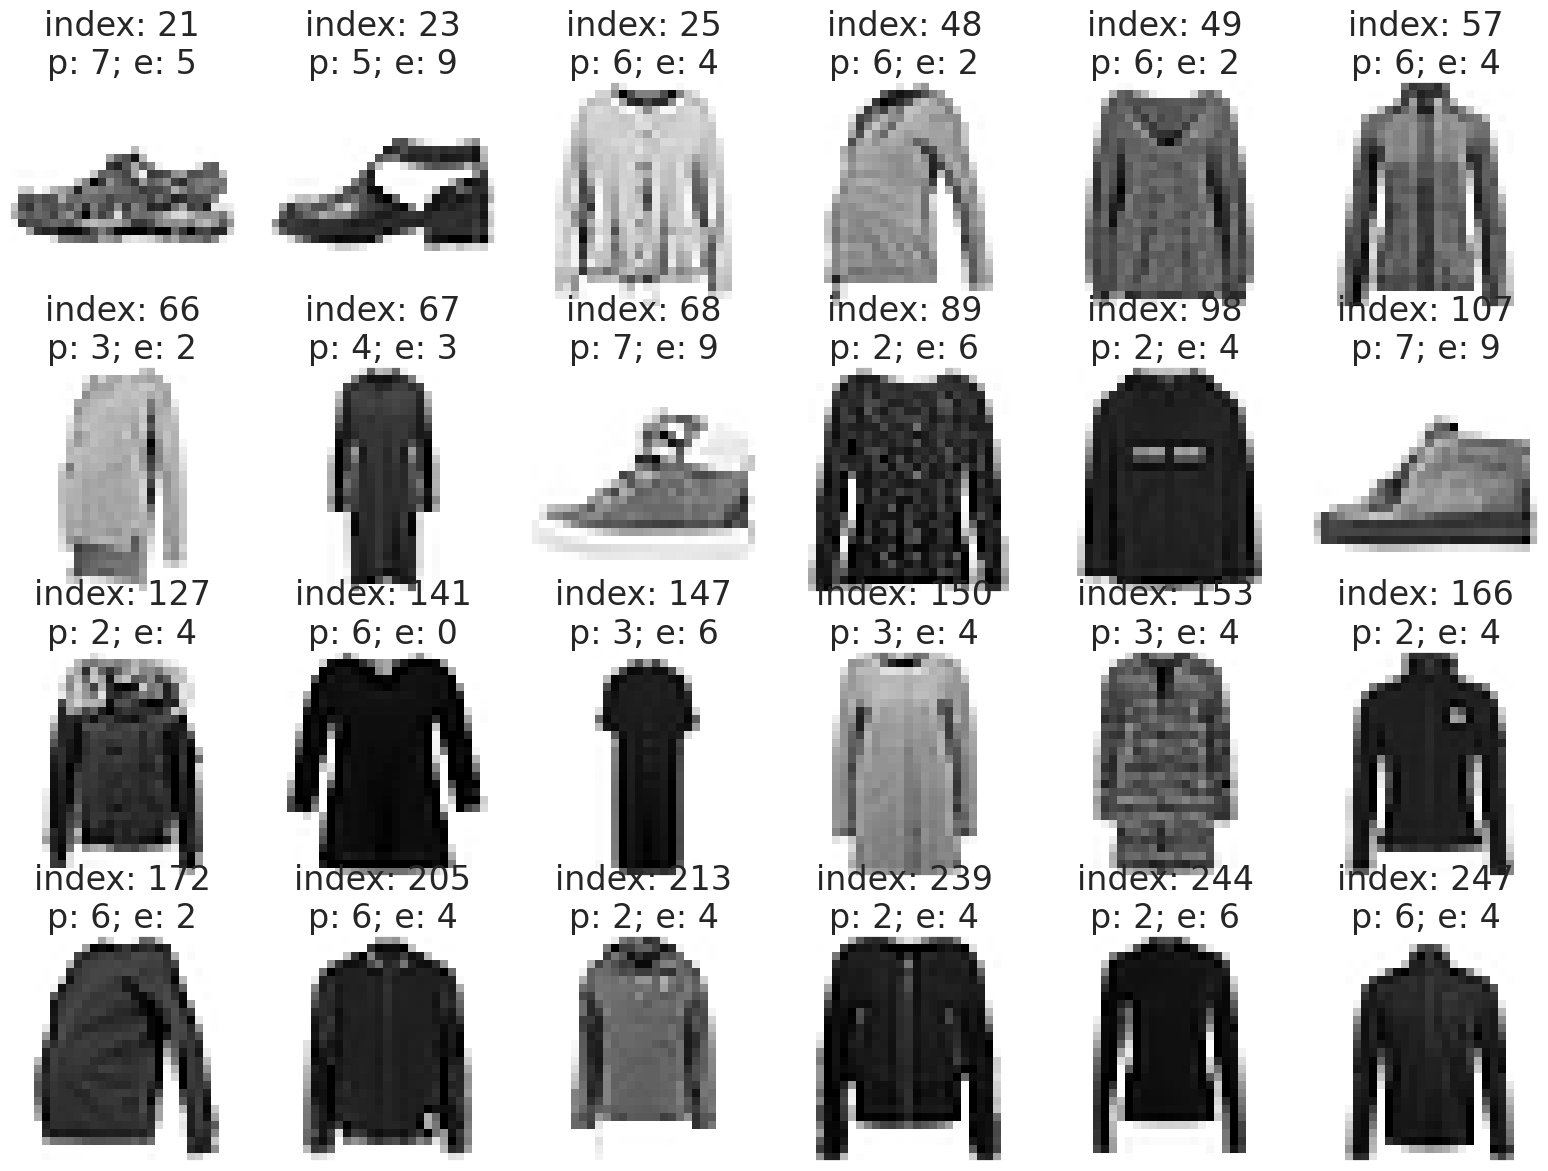

In [13]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dense, Flatten, MaxPooling2D
from tensorflow.keras.utils import plot_model
from IPython.display import Image

sns.set(font_scale=2)

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

index = np.random.choice(np.arange(len(X_train)), 24, replace = False)
figure, axes = plt.subplots(nrows = 4, ncols = 6, figsize = (16,9))

for item in zip(axes.ravel(), X_train[index], y_train[index]):
	axes, image, target = item
	axes.imshow(image, cmap=plt.cm.gray_r)
	axes.set_xticks([])
	axes.set_yticks([])
	axes.set_title(target)
	plt.tight_layout()

X_train = X_train.reshape((60000, 28, 28, 1))
print()
print(X_train.shape)
X_test = X_test.reshape((10000, 28, 28, 1))
print()
print(X_test.shape)

X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255

y_train = to_categorical(y_train)
print()
print(y_train.shape)
y_train[0]
y_test = to_categorical(y_test)
print()
print(y_test.shape)
print()

cnn = Sequential()

cnn.add(Conv2D(filters = 64, kernel_size = (3,3), activation = 'relu', input_shape = (28,28,1)))

cnn.add(MaxPooling2D(pool_size = (2, 2)))

cnn.add(Conv2D(filters = 128, kernel_size = (3, 3), activation = 'relu'))

cnn.add(MaxPooling2D(pool_size = (2, 2)))

cnn.add(Flatten())

cnn.add(Dense(units = 4096))
cnn.add(Dense(units = 128, activation = 'relu'))

cnn.add(Dense(units = 10, activation = 'softmax'))

plot_model(cnn, to_file = 'convnet.png', show_shapes = True, show_layer_names = True)
Image(filename = 'convnet.png')

cnn.compile( optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

cnn.fit(X_train, y_train, epochs = 5, batch_size = 64, validation_split = 0.1)

loss, accuracy = cnn.evaluate(X_test, y_test)

predictions = cnn.predict(X_test)
y_test[0]

for index, probability in enumerate( predictions[0]):
	print(f'{index}: {probability:.10%}')

images = X_test.reshape((10000, 28, 28))
incorrect_predictions = []

for i, (p, e) in enumerate(zip(predictions, y_test)):
  predicted, expected = np.argmax(p), np.argmax(e)
  if predicted != expected:
      incorrect_predictions.append((i, images[i], predicted, expected))

len(incorrect_predictions)

figure, axes = plt.subplots(nrows=4, ncols=6, figsize=(16, 12))

for axes, item in zip(axes.ravel(), incorrect_predictions):
          index, image, predicted, expected = item
          axes.imshow(image, cmap=plt.cm.gray_r)
          axes.set_xticks([])
          axes.set_yticks([])
          axes.set_title( f'index: {index}\np: {predicted}; e: {expected}')
          plt.tight_layout()

def display_probabilities(prediction):
  for index, probability in enumerate(prediction):
    print(f'{index}: {probability:.10%}')

display_probabilities(predictions[495])
print()
display_probabilities(predictions[583])
print()
display_probabilities(predictions[625])


#1. After running fashion mnist I realized it has lower accuracy because fashion mnist has a more complex
# shape, and more variations given the shape and overlapping layers in clothing.

#2. When I added another dense layer of 4,096 neurons it took way longer to process at about 8:1, which online says may lead to overfitting,
# which I think may be an issue since it got a higher accuracy rating. To verify I would have to have more test data.




